# MLP и автоэнкодеры для табличных данных

В этом ноутбуке мы разберём задачу обнаружения мошеннических банковских транзакций и на её примере изучим:

- Устройство многослойного перцептрона (MLP).
- Подготовку табличных данных для нейросети.
- Проблему сильного дисбаланса классов.
- Почему `accuracy` может вводить в заблуждение.
- Основную метрику `Average Precision (AP)`; дополнительно — `Precision`, `Recall`, `F1`, `ROC-AUC`.
- `Dropout`, `Batch Normalization` и L2-регуляризацию.
- Автоэнкодер как модель для anomaly detection.
- Reconstruction error как anomaly score.
- Выбор порога для бинарного детектора (для AP порог не нужен).

> **Идея задачи:** мошеннические транзакции встречаются очень редко.  
> Мы рассмотрим два подхода:
>
> 1. **Supervised:** MLP учится напрямую различать `normal` и `fraud`.
> 2. **Anomaly detection:** автоэнкодер обучается только на нормальных транзакциях, а необычные объекты ищутся по большой ошибке восстановления.

**Запуск:** откройте notebook в Google Colab или Kaggle Notebooks и выполните все
ячейки по порядку (Run all). Нужен доступ в интернет для загрузки Credit Card;
в Kaggle включите Internet в настройках сессии. GPU можно включить для ускорения,
но CPU тоже подходит. Установка дополнительных пакетов и загрузка файлов вручную не нужны.

Если это ваша первая практика с DL, сначала выполните `00_pytorch_basics_v2_colab.ipynb`:
там разобраны тензоры, градиенты и шаг обучения, которые здесь используются без подробного повторения.

## Импорты и воспроизводимость

Мы будем использовать уже знакомые вам библиотеки:

- `pandas`, `numpy` — работа с таблицами;
- `scikit-learn` — разбиение данных, масштабирование и метрики;
- `PyTorch` — построение и обучение нейросетей;
- `matplotlib` — визуализация.

Фиксируем random seed для воспроизводимости в одной среде. На CPU и GPU, а также в разных версиях библиотек результаты могут немного отличаться.

In [1]:
import os
import random
import copy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    roc_curve,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## Загрузка Credit Card Fraud Detection

Датасет содержит банковские транзакции. Целевая переменная:

- `Class = 0` — обычная транзакция;
- `Class = 1` — мошенническая транзакция.

Признаки `V1 ... V28` уже были преобразованы методом PCA (principal component analysis, он же метод главных компонент).  
Кроме них нам так же доступны `Time` и `Amount`.

Ниже используется публичная копия из [TensorFlow tutorial](https://www.tensorflow.org/tutorials/structured_data/imbalanced_data).
Читаем её напрямую через `pandas`, без `kagglehub`. Перед разбиением удалим точные
дубли строк, чтобы копии одной записи не попали одновременно в train и test.

In [2]:
DATA_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

df = pd.read_csv(DATA_URL)
df = df.drop_duplicates().reset_index(drop=True)

print(f"\nРазмер датасета: {df.shape}")
print(f"Количество строк: {df.shape[0]:,}")
print(f"Количество колонок: {df.shape[1]}")

df.head()


Размер датасета: (283726, 31)
Количество строк: 283,726
Количество колонок: 31


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Первичный анализ

Давайте внимательнее посмотрим на наш датасет, а именно:

- сколько объектов каждого класса;
- насколько сильный дисбаланс;

In [3]:
class_counts = df["Class"].value_counts().sort_index()
class_share = df["Class"].value_counts(normalize=True).sort_index()

summary = pd.DataFrame({
    "count": class_counts,
    "share": class_share
})
summary.index = ["normal (0)", "fraud (1)"]

display(summary)

,count,share
normal (0),283253,0.998333
fraud (1),473,0.001667


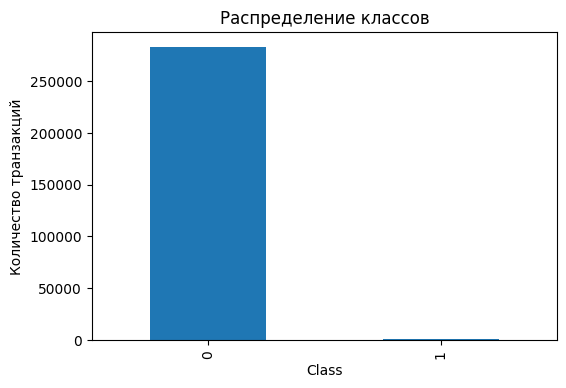

Доля fraud: 0.1667%
Доля normal: 99.8333%


In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
class_counts.plot(kind="bar", ax=ax)
ax.set_title("Распределение классов")
ax.set_xlabel("Class")
ax.set_ylabel("Количество транзакций")
plt.show()

fraud_rate = df["Class"].mean()
print(f"Доля fraud: {fraud_rate:.4%}")
print(f"Доля normal: {1 - fraud_rate:.4%}")

Нетрудно заметить, что разница в соотношении классов просто колоссальная, и её обязательно нужно учитывать при решени задачи.

### Почему Accuracy здесь опасна?

Представим «модель», которая **всегда предсказывает `normal`**.

Если fraud составляет лишь малую долю выборки, такая модель получит почти идеальную accuracy — но не обнаружит ни одного случая мошенничества.

Это важный общий принцип:

> При сильном дисбалансе классов accuracy почти никогда не должна быть единственной метрикой.

In [5]:
y_all = df["Class"].values
always_normal = np.zeros_like(y_all)

print("Accuracy:", accuracy_score(y_all, always_normal))

# zero_division=0 для защиты от деления на 0, т. к. always_normal вообще не делает
# предсказаний класса 1 (TP = 0 и FP = 0), и знаменатель Precision становится равным нулю

print("Precision:", precision_score(y_all, always_normal, zero_division=0))
print("Recall:", recall_score(y_all, always_normal, zero_division=0))
print("F1:", f1_score(y_all, always_normal, zero_division=0))

Accuracy: 0.9983328986416472
Precision: 0.0
Recall: 0.0
F1: 0.0


## Метрики для fraud detection

Пусть положительный класс — `fraud`.

### Precision

$Precision = \frac{TP}{TP + FP}$
Отвечает на вопрос:

> Среди транзакций, которые модель назвала мошенническими, какая доля действительно является fraud?

Высокий Precision означает мало ложных тревог.

### Recall

$Recall = \frac{TP}{TP + FN}$

Отвечает на вопрос:

> Какую долю всех реальных мошеннических транзакций мы обнаружили?

Высокий Recall означает, что модель пропускает мало fraud.

### F1-score

$F_1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}$

F1 балансирует Precision и Recall, но зависит от выбранного порога, по которому мы определяем, является ли класс положительным.

### ROC-AUC

ROC-кривая показывает зависимость TPR / Recall от FPR при изменении порога; ROC-AUC — площадь под ней. Это качество ранжирования, а не количество ложных тревог. При редком fraud небольшая FPR может соответствовать многим ложным тревогам, поэтому основной метрикой здесь будет AP.


### Average Precision (AP) — основная метрика

Для сильно несбалансированных задач особенно полезна Precision–Recall curve. Это зависимость Precision (из того, что модель назвала фродом, сколько реально оказалось фродом) от Recall (полноты: сколько вообще всего реального фрода в датасете нашла модель) так же при изменении порога.

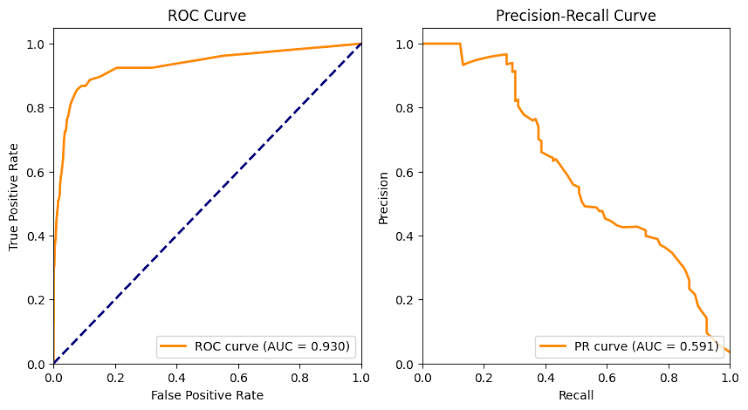

$$ True\ Positive\ Rate = \frac{TP}{TP + FN},\ False\ Positive\ Rate = \frac{FP}{FP + TN}$$

В этом ноутбуке для численной оценки площади будем использовать:

```python
average_precision_score(y_true, score)
```

Это **Average Precision (AP)** — ступенчатая сумма precision по приростам recall, без линейной интерполяции. Она не равна в общем случае трапецеидальной PR-AUC:
$$AP = \sum_n (R_n - R_{n-1})P_n,$$ где $P_n$ и $R_n$ — точность и полнота на $n$-м шаге изменения порога классификации.

Для AP передаём **непрерывные scores**, а не классы: чем выше score, тем подозрительнее
объект. Подбор порога не нужен. Одинаковые scores учитываются одной группой;
грубое округление может изменить AP. Постоянный score даёт AP, равную доле fraud.
В контесте baseline — **Public AP ≥ 0.2**; это порог метрики, а не score объекта.

## Train / Validation / Test split

Разбиваем данные **стратифицированно**, чтобы доля fraud оставалась примерно одинаковой. Без fraud в train модель не сможет учиться распознавать этот класс; без fraud в validation/test нельзя содержательно оценить его обнаружение.

Будем использовать:

- `train` — обучение;
- `validation` — выбор модели и эпохи по AP, threshold;
- `test` — финальная оценка.

Не забываем, что тест нельзя использовать для выбора гиперпараметров.

In [6]:
X = df.drop(columns="Class")
y = df["Class"].astype(np.int64)

X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y,
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train_full,
)

for name, yy in [
    ("train", y_train),
    ("validation", y_val),
    ("test", y_test),
]:
    print(
        f"{name:10s} | n={len(yy):6d} | "
        f"fraud={yy.sum():4d} | fraud share={yy.mean():.4%}"
    )

train      | n=181584 | fraud= 302 | fraud share=0.1663%
validation | n= 45396 | fraud=  76 | fraud share=0.1674%
test       | n= 56746 | fraud=  95 | fraud share=0.1674%


## Масштабирование признаков

Нейросети (как и обычные ML-алгоритмы) обычно обучаются стабильнее, когда входные признаки имеют сопоставимый масштаб.

Особенно важно масштабировать:

- `Time`;
- `Amount`.

Это секунды от начала сбора данных (от 0 до сотен тысяч), а Amount — это сумма транзакции (могут быть как нулями, так и тысячами). Без нормализации эти два признака будут иметь гигантские абсолютные значения по сравнению с остальными.

`V1 ... V28` уже преобразованы PCA (они уже центрированы вокруг нуля и имеют компактный разброс), но для единообразия применим `StandardScaler` ко всем признакам.

**Критически важно:** `scaler.fit(...)` делается только на train.

In [7]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train).astype(np.float32)
X_val_scaled = scaler.transform(X_val).astype(np.float32)
X_test_scaled = scaler.transform(X_test).astype(np.float32)

y_train_np = y_train.to_numpy().astype(np.float32)
y_val_np = y_val.to_numpy().astype(np.float32)
y_test_np = y_test.to_numpy().astype(np.float32)

print(X_train_scaled.shape, X_val_scaled.shape, X_test_scaled.shape)

(181584, 30) (45396, 30) (56746, 30)


## DataLoader

`DataLoader` разбивает данные на мини-батчи для обучения.

Для обычного supervised MLP батч содержит:

```text
(features, label)
```

In [8]:
BATCH_SIZE = 1024

train_ds = TensorDataset(
    torch.tensor(X_train_scaled),
    torch.tensor(y_train_np),
)
val_ds = TensorDataset(
    torch.tensor(X_val_scaled),
    torch.tensor(y_val_np),
)
test_ds = TensorDataset(
    torch.tensor(X_test_scaled),
    torch.tensor(y_test_np),
)

# shuffle=True тут важен, чтобы при обучении нейросеть не запоминала порядок примеров и каждый раз видела батчи в новой случайной комбинации
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)

# А вот оценка модели на валидации и тесте должна быть детерминированной. Если включить shuffle=True,
# порядок батчей каждый раз будет случайным. Из-за этого некоторые метрики могут плавать от запуска к запуску,
# и вам будет тяжело сравнивать разные эксперименты между собой.
# В нашем случае перестановка пар (label, score) сама по себе AP/F1 не меняет, но оставим shuffle=False как правило хорошего тона
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

# Часть I. Supervised MLP

Перейдем к самой главной части этого урока. Итак, как вы уже знаете из лекций, MLP — это последовательность полносвязных слоёв.

Для одного слоя:

$z = Wx + b$, где W - матрица весов, b - смещение, он же bias.

После этого применяется нелинейная функция активации для моделирования нелинейных зависимостей в данных:

Например, `ReLU`: $ReLU(z)=\max(0,z)$, или `Sigmoid`: $h = \sigma(z)$.


Если последовательно использовать только линейные преобразования без функции активации, вся сеть математически сведётся к одному линейному преобразованию. Поэтому нелинейности критически важны.

В бинарной классификации (которой, по сути и является поиск аномалий) удобно выдавать один **logit** (сырое, ненормированное вещественное число, которые выдает последний линейный слой нейросети) и использовать `BCEWithLogitsLoss` (Binary Cross-Entropy Loss).

P. S. За счет грамотных математических преобразований `BCEWithLogitsLoss` является более вычислительно устойчивым, чем последовательное применение `Sigmoid` и `BCELoss`, поэтому предпочтение отдаем именно ему.

Сформируем наш персептрон:

In [9]:
class MLP(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dims=(64, 32),
        dropout=0.0,
        use_batchnorm=False,
    ):
        super().__init__()

        layers = []
        prev_dim = input_dim

        for hidden_dim in hidden_dims:
            layers.append(nn.Linear(prev_dim, hidden_dim))

            if use_batchnorm:
                layers.append(nn.BatchNorm1d(hidden_dim))

            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            prev_dim = hidden_dim

        layers.append(nn.Linear(prev_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(1)


input_dim = X_train_scaled.shape[1]

baseline_mlp = MLP(
    input_dim=input_dim,
    hidden_dims=(64, 32),
    dropout=0.0,
    use_batchnorm=False,
).to(device)

baseline_mlp

MLP(
  (net): Sequential(
    (0): Linear(in_features=30, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)

## Dropout, BatchNorm и L2-регуляризация

### Dropout

Во время обучения зануляет каждую активацию с вероятностью $p$ и масштабирует оставшиеся; сами веса не зануляются. В режиме `eval()` Dropout отключён. Идея в том, что сеть не должна слишком сильно зависеть от отдельных нейронов. При грамотном применении позволяет усилить обобщающую способность сети.

### Batch Normalization

Нормализует промежуточные представления внутри мини-батча (то есть считает среднее значение и дисперсия признаков по батчу) и затем обучает собственные параметры масштаба и сдвига (иногда нейросети нужно более широкое или смещенное распределение, например, чтобы не «убивать» нелинейность функций активации вроде ReLU для отрицательных значений). Часто помогает сделать обучение более стабильным, так как борется со изменением распределения данных в процессе обучения. В `train()` использует статистики текущего батча и обновляет накопленные оценки; в `eval()` использует накопленные оценки.

### L2-регуляризация

Как вы знаете из лекций, штрафует большие веса пропорционально квадрату их нормы. В примерах ниже `AdamW(weight_decay=...)` отдельно уменьшает веса на каждом шаге. При грамотной настройке, как и Dropout, препятствует переобучению и повышает обобщающую способность.

## Loss для несбалансированной классификации

Fraud в нашей выборке очень редок (его доля меньше процента!), поэтому можно сильнее учитывать положительные примеры в функции потерь.

Для `BCEWithLogitsLoss` есть параметр `pos_weight`.

Используем:

$pos\_weight = \frac{N_{negative}}{N_{positive}}$

Это не единственный способ борьбы с дисбалансом, но хороший baseline. Позже можно попробовать другие веса.

In [10]:
n_pos = y_train.sum()
n_neg = len(y_train) - n_pos

pos_weight_value = n_neg / n_pos
pos_weight = torch.tensor([pos_weight_value], dtype=torch.float32, device=device)

print("pos_weight:", float(pos_weight_value))

pos_weight: 600.2715231788079


## Функции обучения

Будем отслеживать loss, но сохранять лучшую модель по **validation AP**.
Градиенты считаются для BCE: AP используется только для выбора эпохи.

Для учебного ноутбука используем небольшой `patience` для early stopping.

In [11]:
def train_classifier(
    model,
    train_loader,
    val_loader,
    epochs=20,
    lr=1e-3,
    weight_decay=0.0,
    patience=4,
):
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    history = {"train_loss": [], "val_loss": [], "val_ap": []}
    best_val_ap = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item() * len(xb))

        model.eval()
        val_losses = []
        val_scores, val_targets = [], []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                yb = yb.to(device)

                logits = model(xb)
                loss = criterion(logits, yb)
                val_losses.append(loss.item() * len(xb))
                val_scores.append(torch.sigmoid(logits).cpu().numpy())
                val_targets.append(yb.cpu().numpy())

        train_loss = np.sum(train_losses) / len(train_loader.dataset)
        val_loss = np.sum(val_losses) / len(val_loader.dataset)
        val_ap = average_precision_score(np.concatenate(val_targets), np.concatenate(val_scores))

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_ap"].append(val_ap)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.5f} | "
            f"val_loss={val_loss:.5f} | val_AP={val_ap:.5f}"
        )

        if val_ap > best_val_ap:
            best_val_ap = val_ap
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            print("Early stopping")
            break

    model.load_state_dict(best_state)
    return history


def predict_classifier(model, loader):
    model.eval()

    all_probs = []
    all_targets = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)

            logits = model(xb)
            probs = torch.sigmoid(logits)

            all_probs.append(probs.cpu().numpy())
            all_targets.append(yb.numpy())

    return np.concatenate(all_targets), np.concatenate(all_probs)

## Обучаем baseline MLP

In [12]:
baseline_mlp = MLP(
    input_dim=input_dim,
    hidden_dims=(64, 32),
    dropout=0.0,
    use_batchnorm=False,
).to(device)

history_baseline = train_classifier(
    baseline_mlp,
    train_loader,
    val_loader,
    epochs=20,
    lr=1e-3,
    weight_decay=0.0,
)

Epoch 01 | train_loss=0.64107 | val_loss=0.34501 | val_AP=0.80120
Epoch 02 | train_loss=0.30813 | val_loss=0.31938 | val_AP=0.79387
Epoch 03 | train_loss=0.24257 | val_loss=0.31858 | val_AP=0.81282
Epoch 04 | train_loss=0.21333 | val_loss=0.31368 | val_AP=0.81595
Epoch 05 | train_loss=0.19593 | val_loss=0.32329 | val_AP=0.80230
Epoch 06 | train_loss=0.16717 | val_loss=0.38240 | val_AP=0.81605
Epoch 07 | train_loss=0.15178 | val_loss=0.37444 | val_AP=0.82164
Epoch 08 | train_loss=0.14016 | val_loss=0.38678 | val_AP=0.80752
Epoch 09 | train_loss=0.11983 | val_loss=0.41556 | val_AP=0.81937
Epoch 10 | train_loss=0.10432 | val_loss=0.42455 | val_AP=0.82022
Epoch 11 | train_loss=0.09706 | val_loss=0.44974 | val_AP=0.78748
Early stopping


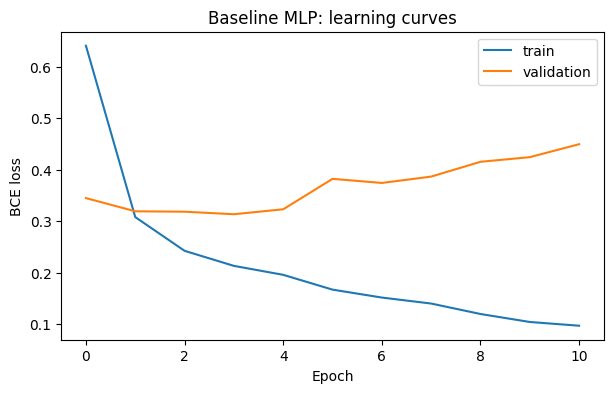

In [13]:
plt.figure(figsize=(7, 4))
plt.plot(history_baseline["train_loss"], label="train")
plt.plot(history_baseline["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("BCE loss")
plt.title("Baseline MLP: learning curves")
plt.legend()
plt.show()

## Оценка модели: score и threshold

После sigmoid MLP выдаёт score от 0 до 1. Score не обязан быть калиброванной вероятностью fraud.

Для основной метрики AP используем score напрямую. Для дополнительных `Precision`, `Recall`, `F1` нужен порог, превращающий score в класс.

Стандартный threshold `0.5` не обязательно оптимален.

Сначала оценим threshold-independent метрики:

- **Average Precision**;
- ROC-AUC (дополнительно).

In [14]:
y_val_true, val_probs = predict_classifier(baseline_mlp, val_loader)

print("ROC-AUC:", roc_auc_score(y_val_true, val_probs))
print("Average Precision:", average_precision_score(y_val_true, val_probs))

ROC-AUC: 0.9762873368328147
Average Precision: 0.8216377046529407


## Precision–Recall curve

На PR-кривой точки соответствуют разным threshold.

Это позволяет увидеть trade-off:

- более низкий threshold → больше Recall, но обычно ниже Precision;
- более высокий threshold → выше Precision, но часть fraud будет пропущена.

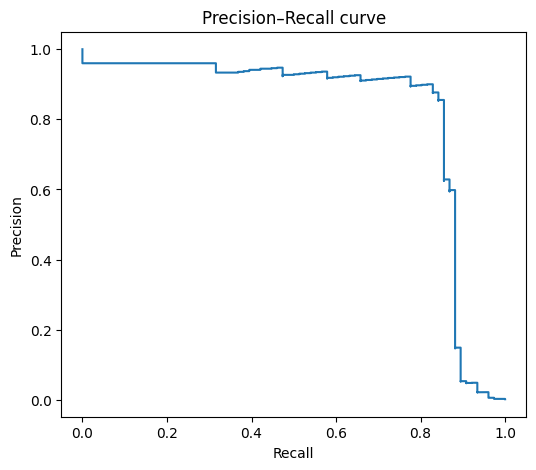

In [15]:
precision, recall, thresholds = precision_recall_curve(y_val_true, val_probs)

plt.figure(figsize=(6, 5))
plt.step(recall, precision, where="post")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall curve")
plt.show()

## Дополнительно: подбираем threshold по F1

Для учебного эксперимента найдём threshold, максимизирующий F1 на validation.

**Важно:** этот threshold нельзя подбирать на test.

In [16]:
def find_best_f1_threshold(y_true, scores):
    precision, recall, thresholds = precision_recall_curve(y_true, scores)

    f1 = 2 * precision * recall / (precision + recall + 1e-12)

    # precision_recall_curve возвращает на одну precision/recall точку больше
    best_idx = np.argmax(f1[:-1])

    return {
        "threshold": thresholds[best_idx],
        "f1": f1[best_idx],
        "precision": precision[best_idx],
        "recall": recall[best_idx],
    }


best_threshold_info = find_best_f1_threshold(y_val_true, val_probs)
best_threshold_info

{'threshold': np.float32(0.9993331),
 'f1': np.float64(0.8630136986296378),
 'precision': np.float64(0.9),
 'recall': np.float64(0.8289473684210527)}

In [17]:
def classification_report_at_threshold(y_true, scores, threshold):
    y_pred = (scores >= threshold).astype(int)

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, scores),
        "average_precision": average_precision_score(y_true, scores),
    }

    return pd.Series(metrics)


display(
    classification_report_at_threshold(
        y_val_true,
        val_probs,
        threshold=best_threshold_info["threshold"],
    )
)

,0
accuracy,0.999559
precision,0.900000
recall,0.828947
f1,0.863014
roc_auc,0.976287
average_precision,0.821638


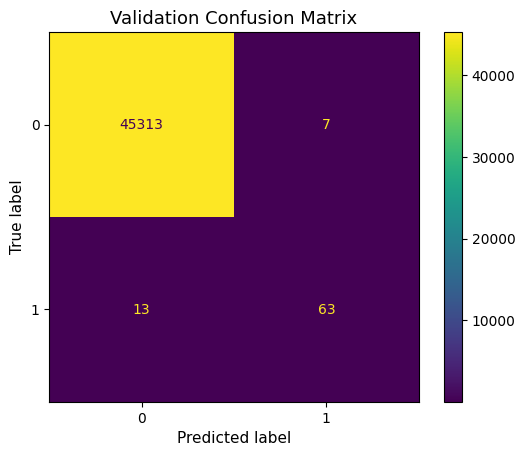

In [18]:
y_val_pred = (val_probs >= best_threshold_info["threshold"]).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_val_true,
    y_val_pred,
    values_format="d",
    display_labels=["0", "1"],
)

disp.ax_.set_xlabel("Predicted label", fontsize=11)
disp.ax_.set_ylabel("True label", fontsize=11)

plt.title("Validation Confusion Matrix", fontsize=13)
plt.show()

## Эксперимент: Dropout, BatchNorm, L2

Теперь сравним несколько вариантов.

Чтобы сравнение было честнее, оставляем одинаковыми:

- train/validation split;
- hidden dimensions;
- optimizer;
- learning rate;
- число эпох.

Меняем только регуляризацию.

Ранжируем варианты по **validation AP**. В таблице сохранены дополнительные F1-метрики.

In [19]:
experiments = {
    "baseline": {
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
    "dropout": {
        "dropout": 0.2,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
    "batchnorm": {
        "dropout": 0.0,
        "batchnorm": True,
        "weight_decay": 0.0,
    },
    "l2": {
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 1e-4,
    },
    "bn_dropout_l2": {
        "dropout": 0.1,
        "batchnorm": True,
        "weight_decay": 1e-4,
    },
}

classifier_results = []
trained_classifiers = {}

for name, cfg in experiments.items():
    print("\n" + "=" * 70)
    print("Experiment:", name)

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = MLP(
        input_dim=input_dim,
        hidden_dims=(64, 32),
        dropout=cfg["dropout"],
        use_batchnorm=cfg["batchnorm"],
    ).to(device)

    history = train_classifier(
        model,
        train_loader,
        val_loader,
        epochs=15,
        lr=1e-3,
        weight_decay=cfg["weight_decay"],
    )

    y_true_tmp, scores_tmp = predict_classifier(model, val_loader)
    threshold_info = find_best_f1_threshold(y_true_tmp, scores_tmp)

    classifier_results.append({
        "model": name,
        "AP": average_precision_score(y_true_tmp, scores_tmp),
        "ROC_AUC": roc_auc_score(y_true_tmp, scores_tmp),
        "best_F1": threshold_info["f1"],
        "precision_at_best_F1": threshold_info["precision"],
        "recall_at_best_F1": threshold_info["recall"],
        "threshold": threshold_info["threshold"],
    })

    trained_classifiers[name] = model

classifier_results_df = (
    pd.DataFrame(classifier_results)
    .sort_values("AP", ascending=False)
    .reset_index(drop=True)
)

classifier_results_df


Experiment: baseline
Epoch 01 | train_loss=0.57489 | val_loss=0.34655 | val_AP=0.78793
Epoch 02 | train_loss=0.28084 | val_loss=0.32356 | val_AP=0.79968
Epoch 03 | train_loss=0.22784 | val_loss=0.32288 | val_AP=0.81884
Epoch 04 | train_loss=0.19392 | val_loss=0.36150 | val_AP=0.80970
Epoch 05 | train_loss=0.17706 | val_loss=0.36128 | val_AP=0.77763
Epoch 06 | train_loss=0.15996 | val_loss=0.37132 | val_AP=0.79298
Epoch 07 | train_loss=0.14442 | val_loss=0.40535 | val_AP=0.80286
Early stopping

Experiment: dropout
Epoch 01 | train_loss=0.62942 | val_loss=0.35092 | val_AP=0.79146
Epoch 02 | train_loss=0.30894 | val_loss=0.32494 | val_AP=0.79505
Epoch 03 | train_loss=0.24653 | val_loss=0.34058 | val_AP=0.80881
Epoch 04 | train_loss=0.22898 | val_loss=0.34359 | val_AP=0.80679
Epoch 05 | train_loss=0.20874 | val_loss=0.35383 | val_AP=0.81546
Epoch 06 | train_loss=0.20270 | val_loss=0.35671 | val_AP=0.80788
Epoch 07 | train_loss=0.18676 | val_loss=0.37630 | val_AP=0.82596
Epoch 08 | train_l

,model,AP,ROC_AUC,best_F1,precision_at_best_F1,recall_at_best_F1,threshold
0,batchnorm,0.855919,0.952309,0.859060,0.876712,0.842105,0.997034
1,dropout,0.825960,0.974180,0.872483,0.890411,0.855263,0.998267
2,baseline,0.818841,0.977768,0.859060,0.876712,0.842105,0.998281
3,l2,0.818841,0.977767,0.859060,0.876712,0.842105,0.998281
4,bn_dropout_l2,0.805895,0.971967,0.840764,0.814815,0.868421,0.977523


### Глядя на результаты, можно немного порассуждать?

1. Улучшил ли Dropout **validation AP** относительно baseline? Совпадает ли вывод по AP и F1?

По метрике F1-score и precision Dropout показывает лучший результат среди всех моделей, превосходя baseline. Однако по AP (Average Precision) он довольно близок к бейзлайну ($\approx 0.82$), а по ROC_AUC (0.974) незначительно уступает ему (0.978). Таким образом, Dropout улучшил качество классификации на оптимальном пороге (F1), но глобально по ранжированию вероятностей (ROC_AUC/AP) эффект неоднозначен.

2. Улучшил ли BatchNorm validation AP в текущем запуске?

Да. Модель с BatchNorm (batchnorm) демонстрирует лучший результат по AP и ROC_AUC среди всех представленных вариантов, заметно превосходя baseline.

3. Почему нельзя сделать вывод «BatchNorm всегда улучшает нейросеть»?

Эффект зависит от архитектуры, размера батча и данных. При слишком маленьких
батчах оценки среднего и дисперсии могут быть шумными.

4. Почему более сильная регуляризация может ухудшить модель?

Избыточная регуляризация (слишком высокий коэффициент L2-штрафа или большая доля дропаута) приводит к недообучению (underfitting). Модель становится излишне «простой» или теряет способность улавливать сложные закономерности в данных, из-за чего падает её общая предсказательная сила (что мы видим, например, в строке baseline или при комбинациях, где жесткие ограничения снижают AP по сравнению с чистым BatchNorm).

В завершение этой части посмотрим качество на тесте.

In [20]:
best_clf_name = classifier_results_df.iloc[0]["model"]
best_clf_model = trained_classifiers[best_clf_name]

_, val_scores_clf = predict_classifier(best_clf_model, val_loader)
y_true_val, _ = predict_classifier(best_clf_model, val_loader)

best_clf_threshold_info = find_best_f1_threshold(y_val_np, val_scores_clf)

y_test_tmp, test_scores_clf = predict_classifier(best_clf_model, test_loader)

print("Best classifier by validation AP:", best_clf_name)
print("Test ROC-AUC:", roc_auc_score(y_test_np, test_scores_clf))
print("Test Average Precision:", average_precision_score(y_test_np, test_scores_clf))

display(
    classification_report_at_threshold(
        y_test_np,
        test_scores_clf,
        best_clf_threshold_info["threshold"],
    )
)

Best classifier by validation AP: batchnorm
Test ROC-AUC: 0.9460041119727528
Test Average Precision: 0.7236882266995528


,0
accuracy,0.999366
precision,0.855422
recall,0.747368
f1,0.797753
roc_auc,0.946004
average_precision,0.723688


# Часть II. Autoencoder для anomaly detection

## Основная идея

Давайте теперь решим поставленную задачу по-другому, используя немного более сложную архитектуру, в основе которой лежит MLP.

Идея автокодировщика заключается в сжатии входа в скрытое пространство меньшей размерности (энкодер) и в обратном восстановлении данных (декодер). Его обучают исключительно на нормальных примерах, а аномалии выявляют по ошибке реконструкции: когда на вход обученной модели подается нетипичный объект (который сеть раньше не видела), ожидается большая ошибка восстановления. Это гипотеза, а не гарантия: некоторые аномалии сеть тоже может хорошо восстановить.

Короче говоря, автокодировщик состоит из двух частей:

```text
input → encoder → latent representation → decoder → reconstructed input
```

Encoder сжимает объект:

$z = Encoder(x_{input})$

Decoder пытается восстановить исходный объект:

$x_{output}=Decoder(z)$

Если сеть обучалась **только на нормальных транзакциях**, ожидается:

- normal → хорошо восстанавливается;
- anomaly → восстанавливается хуже.

Тогда anomaly score можно определить как reconstruction error:

$score(x)=\frac{1}{d}\sum_j(x_j-\hat{x}_j)^2,$ где d - число признаков объекта.

То есть, чем больше score, тем подозрительнее транзакция.

## Важный принцип: train только на normal

Для autoencoder:

- train: только `Class = 0`;
- validation/test: normal + fraud.

Reconstruction loss не предсказывает метку, но normal train отбирается по разметке.
Validation labels используются для выбора эпохи и модели по **AP**, а также для
дополнительного выбора threshold. Поэтому весь этот эксперимент не является
полностью unsupervised. Метки test используются только для финальной оценки.

In [21]:
normal_train_mask = (y_train_np == 0)

X_ae_train = X_train_scaled[normal_train_mask]

print("AE train shape:", X_ae_train.shape)

AE train shape: (181282, 30)


In [22]:
AE_BATCH_SIZE = 1024

ae_train_ds = TensorDataset(torch.tensor(X_ae_train))
ae_train_loader = DataLoader(
    ae_train_ds,
    batch_size=AE_BATCH_SIZE,
    shuffle=True,
)

ae_val_ds = TensorDataset(
    torch.tensor(X_val_scaled),
    torch.tensor(y_val_np),
)
ae_val_loader = DataLoader(
    ae_val_ds,
    batch_size=AE_BATCH_SIZE,
    shuffle=False,
)

ae_test_ds = TensorDataset(
    torch.tensor(X_test_scaled),
    torch.tensor(y_test_np),
)
ae_test_loader = DataLoader(
    ae_test_ds,
    batch_size=AE_BATCH_SIZE,
    shuffle=False,
)

## Архитектура Autoencoder

Рассмотрим следующий baseline:

```text
30 → 24 → 12 → 6 → 12 → 24 → 30
```

То есть по сути автокодировщик - последовательность сначала сужающихся, а потом расширяющихся линейных слоев (привет, MLP).

Размер bottleneck (`latent_dim`) — важный гиперпараметр.

Слишком маленький latent space может потерять полезную информацию.

Слишком большой — позволяет сети почти копировать вход, из-за чего она может хорошо восстанавливать даже аномалии.

In [23]:
class Autoencoder(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dims=(16, 8),
        latent_dim=4,
        dropout=0.0,
        use_batchnorm=False,
    ):
        super().__init__()

        encoder_layers = []
        prev = input_dim

        for h in hidden_dims:
            encoder_layers.append(nn.Linear(prev, h))
            if use_batchnorm:
                encoder_layers.append(nn.BatchNorm1d(h))
            encoder_layers.append(nn.ReLU())
            if dropout > 0:
                encoder_layers.append(nn.Dropout(dropout))
            prev = h

        encoder_layers.append(nn.Linear(prev, latent_dim))

        decoder_layers = []
        prev = latent_dim

        for h in reversed(hidden_dims):
            decoder_layers.append(nn.Linear(prev, h))
            if use_batchnorm:
                decoder_layers.append(nn.BatchNorm1d(h))
            decoder_layers.append(nn.ReLU())
            if dropout > 0:
                decoder_layers.append(nn.Dropout(dropout))
            prev = h

        decoder_layers.append(nn.Linear(prev, input_dim))

        self.encoder = nn.Sequential(*encoder_layers)
        self.decoder = nn.Sequential(*decoder_layers)

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat


ae_baseline = Autoencoder(
    input_dim=input_dim,
    hidden_dims=(24, 12),
    latent_dim=6,
).to(device)

ae_baseline

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=30, out_features=24, bias=True)
    (1): ReLU()
    (2): Linear(in_features=24, out_features=12, bias=True)
    (3): ReLU()
    (4): Linear(in_features=12, out_features=6, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=6, out_features=12, bias=True)
    (1): ReLU()
    (2): Linear(in_features=12, out_features=24, bias=True)
    (3): ReLU()
    (4): Linear(in_features=24, out_features=30, bias=True)
  )
)

## Обучение Autoencoder

В качестве ошибки реконструкции используем MSE:

$MSE(x,\hat{x})$

На каждой эпохе считаем reconstruction loss на train.

Градиенты считаем только по MSE normal train. Для early stopping выбираем
максимальную **AP на всей validation** (normal + fraud); MSE normal validation
остаётся диагностикой. Так выбираем детектор по качеству ранжирования, используя
validation labels, но не обучая реконструкцию на fraud.

In [24]:
def train_autoencoder(
    model,
    train_loader,
    val_loader,
    epochs=30,
    lr=1e-3,
    weight_decay=0.0,
    patience=5,
):
    criterion = nn.MSELoss()
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    history = {"train_loss": [], "val_normal_loss": [], "val_ap": []}
    best_val_ap = -float("inf")
    best_state = copy.deepcopy(model.state_dict())
    bad_epochs = 0

    for epoch in range(1, epochs + 1):
        model.train()
        train_losses = []

        for (xb,) in train_loader:
            xb = xb.to(device)

            optimizer.zero_grad()
            x_hat = model(xb)
            loss = criterion(x_hat, xb)
            loss.backward()
            optimizer.step()

            train_losses.append(loss.item() * len(xb))

        model.eval()
        val_scores, val_targets = [], []

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(device)
                x_hat = model(xb)
                scores = torch.mean((xb - x_hat) ** 2, dim=1)
                val_scores.append(scores.cpu().numpy())
                val_targets.append(yb.numpy())

        train_loss = np.sum(train_losses) / len(train_loader.dataset)
        val_scores = np.concatenate(val_scores)
        val_targets = np.concatenate(val_targets)
        val_loss = np.mean(val_scores[val_targets == 0])
        val_ap = average_precision_score(val_targets, val_scores)

        history["train_loss"].append(train_loss)
        history["val_normal_loss"].append(val_loss)
        history["val_ap"].append(val_ap)

        print(
            f"Epoch {epoch:02d} | "
            f"train_loss={train_loss:.6f} | "
            f"val_normal_loss={val_loss:.6f} | val_AP={val_ap:.5f}"
        )

        if val_ap > best_val_ap:
            best_val_ap = val_ap
            best_state = copy.deepcopy(model.state_dict())
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= patience:
            print("Early stopping")
            break

    model.load_state_dict(best_state)
    return history

In [25]:
ae_baseline = Autoencoder(
    input_dim=input_dim,
    hidden_dims=(24, 12),
    latent_dim=6,
    dropout=0.0,
    use_batchnorm=False,
).to(device)

history_ae = train_autoencoder(
    ae_baseline,
    ae_train_loader,
    ae_val_loader,
    epochs=50,
    lr=1e-3,
    weight_decay=0.0,
)

Epoch 01 | train_loss=0.891309 | val_normal_loss=0.767506 | val_AP=0.22842
Epoch 02 | train_loss=0.747308 | val_normal_loss=0.689104 | val_AP=0.25558
Epoch 03 | train_loss=0.659105 | val_normal_loss=0.605176 | val_AP=0.30793
Epoch 04 | train_loss=0.574256 | val_normal_loss=0.534308 | val_AP=0.37267
Epoch 05 | train_loss=0.524873 | val_normal_loss=0.510066 | val_AP=0.39729
Epoch 06 | train_loss=0.508198 | val_normal_loss=0.493950 | val_AP=0.41689
Epoch 07 | train_loss=0.492955 | val_normal_loss=0.482474 | val_AP=0.42770
Epoch 08 | train_loss=0.482389 | val_normal_loss=0.472990 | val_AP=0.46268
Epoch 09 | train_loss=0.473044 | val_normal_loss=0.465212 | val_AP=0.48051
Epoch 10 | train_loss=0.465405 | val_normal_loss=0.455301 | val_AP=0.49685
Epoch 11 | train_loss=0.457059 | val_normal_loss=0.447684 | val_AP=0.50696
Epoch 12 | train_loss=0.449983 | val_normal_loss=0.442143 | val_AP=0.51531
Epoch 13 | train_loss=0.443701 | val_normal_loss=0.435666 | val_AP=0.52168
Epoch 14 | train_loss=0.4

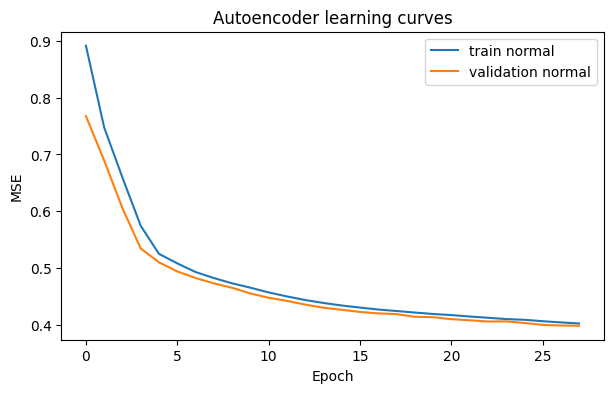

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(history_ae["train_loss"], label="train normal")
plt.plot(history_ae["val_normal_loss"], label="validation normal")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Autoencoder learning curves")
plt.legend()
plt.show()

## Reconstruction error → anomaly score

In [27]:
def autoencoder_scores(model, X_scaled, batch_size=2048):
    model.eval()

    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    loader = DataLoader(
        TensorDataset(X_tensor),
        batch_size=batch_size,
        shuffle=False,
    )

    scores = []

    with torch.no_grad():
        for (xb,) in loader:
            xb = xb.to(device)
            x_hat = model(xb)

            batch_scores = torch.mean(
                (xb - x_hat) ** 2,
                dim=1,
            )

            scores.append(batch_scores.cpu().numpy())

    return np.concatenate(scores)


val_ae_scores = autoencoder_scores(ae_baseline, X_val_scaled)

print("Validation AP:", average_precision_score(y_val_np, val_ae_scores))
print("Validation ROC-AUC:", roc_auc_score(y_val_np, val_ae_scores))

Validation AP: 0.5396396425427866
Validation ROC-AUC: 0.9448820086403121


## Сравним reconstruction error normal и fraud

Если идея anomaly detection работает, распределение fraud должно быть смещено в сторону больших ошибок восстановления.

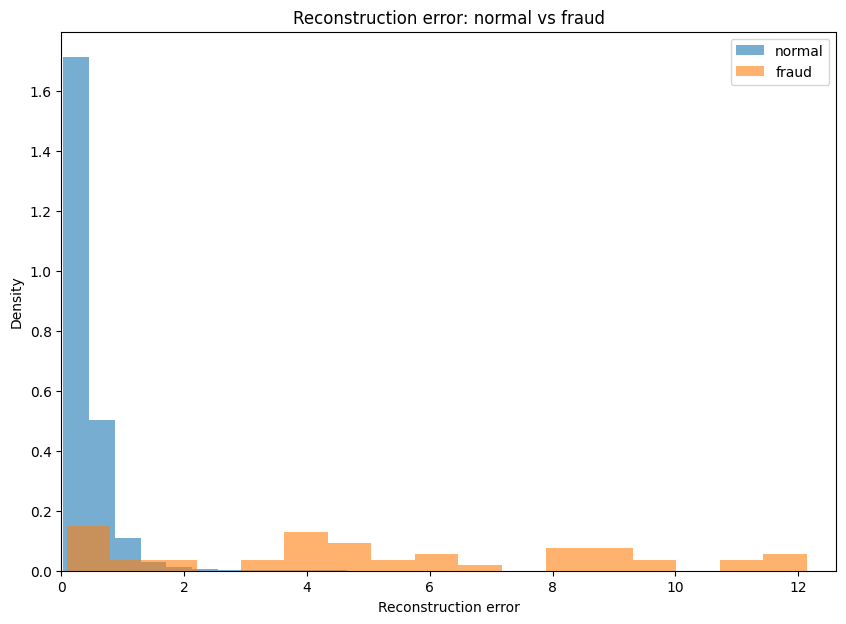

Median normal score: 0.29252458
Median fraud score: 9.11376


In [28]:
normal_scores = val_ae_scores[y_val_np == 0]
fraud_scores = val_ae_scores[y_val_np == 1]

plt.figure(figsize=(10, 7))
plt.hist(
    normal_scores,
    bins=100,
    alpha=0.6,
    density=True,
    label="normal",
)
plt.hist(
    fraud_scores,
    bins=100,
    alpha=0.6,
    density=True,
    label="fraud",
)

plt.xlim(
    0,
    np.percentile(val_ae_scores, 99.9),
)
plt.xlabel("Reconstruction error")
plt.ylabel("Density")
plt.title("Reconstruction error: normal vs fraud")
plt.legend()
plt.show()

print("Median normal score:", np.median(normal_scores))
print("Median fraud score:", np.median(fraud_scores))

## Precision–Recall curve для Autoencoder

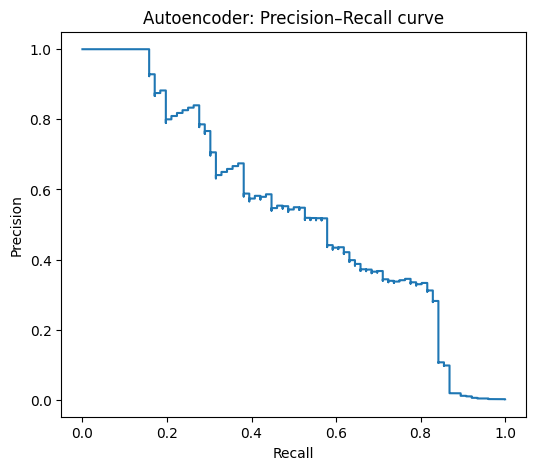

In [29]:
precision_ae, recall_ae, thresholds_ae = precision_recall_curve(
    y_val_np,
    val_ae_scores,
)

plt.figure(figsize=(6, 5))
plt.step(recall_ae, precision_ae, where="post")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Autoencoder: Precision–Recall curve")
plt.show()

## Дополнительно: threshold для anomaly detector

Для бинарного решения «аномалия / норма» можем выбрать threshold двумя способами. На AP этот выбор не влияет.

### Вариант A. Максимальный F1 на validation

Использует labels validation.

### Вариант B. Percentile normal reconstruction error

Например:

$threshold = P_{99.5}(error_{normal})$ (берем 99.5-й перцентиль от ошибки реконструкции)

Здесь normal validation тоже отбирается по меткам. Перцентиль задаёт частоту тревог на этих normal-примерах, но не гарантирует её на новых данных.

In [30]:
best_ae_threshold = find_best_f1_threshold(
    y_val_np,
    val_ae_scores,
)

percentile_threshold = np.percentile(
    val_ae_scores[y_val_np == 0],
    99.5,
)

print("Best F1 threshold:")
print(best_ae_threshold)

print("\n99.5 percentile normal threshold:")
print(percentile_threshold)

Best F1 threshold:
{'threshold': np.float32(8.381669), 'f1': np.float64(0.5465838509311787), 'precision': np.float64(0.5176470588235295), 'recall': np.float64(0.5789473684210527)}

99.5 percentile normal threshold:
2.6515481


In [31]:
display(
    classification_report_at_threshold(
        y_val_np,
        val_ae_scores,
        best_ae_threshold["threshold"],
    )
)

,0
accuracy,0.998392
precision,0.517647
recall,0.578947
f1,0.546584
roc_auc,0.944882
average_precision,0.539640


In [32]:
display(
    classification_report_at_threshold(
        y_val_np,
        val_ae_scores,
        percentile_threshold,
    )
)

,0
accuracy,0.994735
precision,0.219931
recall,0.842105
f1,0.348774
roc_auc,0.944882
average_precision,0.539640


F1 на этой validation при подборе порога по F1 не ниже, чем при другом пороге. Это следствие оптимизации на тех же данных, а не гарантия преимущества на test; AP у двух вариантов порога одна и та же.

## Сравнение supervised MLP и Autoencoder


### Supervised MLP

Использует fraud labels при обучении.

Плюсы:

- обычно сильнее, если размеченных fraud достаточно;
- напрямую оптимизирует классификацию.

Минусы:

- зависит от качества и полноты разметки;
- может плохо реагировать на принципиально новые типы fraud.

### Autoencoder

Обучается только на normal.

Плюсы:

- можно обучать без размеченных аномалий;
- естественная постановка для novelty detection.

Минусы:

- высокая reconstruction error не гарантирует, что объект действительно fraud;
- слишком мощный автоэнкодер может хорошо восстанавливать аномалии;
- выбор архитектуры и preprocessing сильно влияет на качество.

In [33]:
ae_experiments = {
    "baseline": {
        "hidden_dims": (16, 8),
        "latent_dim": 4,
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
    "dropout_0.1": {
        "hidden_dims": (16, 8),
        "latent_dim": 4,
        "dropout": 0.1,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
    "batchnorm": {
        "hidden_dims": (16, 8),
        "latent_dim": 4,
        "dropout": 0.0,
        "batchnorm": True,
        "weight_decay": 0.0,
    },
    "l2": {
        "hidden_dims": (16, 8),
        "latent_dim": 4,
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 1e-4,
    },
    "latent_8": {
        "hidden_dims": (32, 16),
        "latent_dim": 8,
        "dropout": 0.0,
        "batchnorm": False,
        "weight_decay": 0.0,
    },
}

ae_results = []
trained_autoencoders = {}

for name, cfg in ae_experiments.items():
    print("\n" + "=" * 70)
    print("Experiment:", name)

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = Autoencoder(
        input_dim=input_dim,
        hidden_dims=cfg["hidden_dims"],
        latent_dim=cfg["latent_dim"],
        dropout=cfg["dropout"],
        use_batchnorm=cfg["batchnorm"],
    ).to(device)

    history = train_autoencoder(
        model,
        ae_train_loader,
        ae_val_loader,
        epochs=20,
        lr=1e-3,
        weight_decay=cfg["weight_decay"],
    )

    scores = autoencoder_scores(model, X_val_scaled)
    threshold_info = find_best_f1_threshold(y_val_np, scores)

    ae_results.append({
        "model": name,
        "AP": average_precision_score(y_val_np, scores),
        "ROC_AUC": roc_auc_score(y_val_np, scores),
        "best_F1": threshold_info["f1"],
        "precision_at_best_F1": threshold_info["precision"],
        "recall_at_best_F1": threshold_info["recall"],
        "threshold": threshold_info["threshold"],
    })

    trained_autoencoders[name] = model

ae_results_df = (
    pd.DataFrame(ae_results)
    .sort_values("AP", ascending=False)
    .reset_index(drop=True)
)

ae_results_df


Experiment: baseline
Epoch 01 | train_loss=0.941058 | val_normal_loss=0.862063 | val_AP=0.17321
Epoch 02 | train_loss=0.818732 | val_normal_loss=0.736801 | val_AP=0.24585
Epoch 03 | train_loss=0.721390 | val_normal_loss=0.669730 | val_AP=0.27625
Epoch 04 | train_loss=0.675610 | val_normal_loss=0.645282 | val_AP=0.29038
Epoch 05 | train_loss=0.655931 | val_normal_loss=0.628535 | val_AP=0.30402
Epoch 06 | train_loss=0.638998 | val_normal_loss=0.613503 | val_AP=0.32302
Epoch 07 | train_loss=0.624285 | val_normal_loss=0.600915 | val_AP=0.33757
Epoch 08 | train_loss=0.609316 | val_normal_loss=0.587225 | val_AP=0.36326
Epoch 09 | train_loss=0.594095 | val_normal_loss=0.578892 | val_AP=0.37558
Epoch 10 | train_loss=0.587972 | val_normal_loss=0.569207 | val_AP=0.38654
Epoch 11 | train_loss=0.577855 | val_normal_loss=0.563575 | val_AP=0.39422
Epoch 12 | train_loss=0.572422 | val_normal_loss=0.559722 | val_AP=0.40145
Epoch 13 | train_loss=0.567337 | val_normal_loss=0.554375 | val_AP=0.40972
Epo

,model,AP,ROC_AUC,best_F1,precision_at_best_F1,recall_at_best_F1,threshold
0,latent_8,0.654873,0.948446,0.666667,0.785714,0.578947,8.182120
1,l2,0.437098,0.954848,0.497297,0.422018,0.605263,8.439398
2,baseline,0.434527,0.954268,0.505495,0.433962,0.605263,8.503764
3,batchnorm,0.342185,0.957058,0.418605,0.375000,0.473684,11.854601
4,dropout_0.1,0.295674,0.947931,0.339623,0.264706,0.473684,11.671904


# Часть III. Финальная оценка на Test

До этого момента test не должен был влиять на решения.

Выбираем модель по validation и только один раз оцениваем её на test.

Сначала сравним лучшую validation AP среди MLP и AE и зафиксируем победителя. Ни его архитектуру, ни порог после просмотра test не меняем.

In [34]:
best_ae_name = ae_results_df.iloc[0]["model"]
best_ae_model = trained_autoencoders[best_ae_name]

best_ae_val_scores = autoencoder_scores(best_ae_model, X_val_scaled)
best_ae_threshold_info = find_best_f1_threshold(y_val_np, best_ae_val_scores)

# Выбор семьи модели делается только по validation AP.
if classifier_results_df.iloc[0]["AP"] >= ae_results_df.iloc[0]["AP"]:
    final_name = f"MLP: {best_clf_name}"
    _, test_scores = predict_classifier(best_clf_model, test_loader)
    final_threshold_info = best_clf_threshold_info
else:
    final_name = f"AE: {best_ae_name}"
    test_scores = autoencoder_scores(best_ae_model, X_test_scaled)
    final_threshold_info = best_ae_threshold_info

print("Chosen by validation AP:", final_name)
print("Test Average Precision:", average_precision_score(y_test_np, test_scores))
print("Test ROC-AUC (дополнительно):", roc_auc_score(y_test_np, test_scores))

# Дополнительный бинарный отчёт; порог ранее выбран только на validation.
display(
    classification_report_at_threshold(
        y_test_np,
        test_scores,
        final_threshold_info["threshold"],
    )
)

Chosen by validation AP: MLP: batchnorm
Test Average Precision: 0.7236882266995528
Test ROC-AUC (дополнительно): 0.9460041119727528


,0
accuracy,0.999366
precision,0.855422
recall,0.747368
f1,0.797753
roc_auc,0.946004
average_precision,0.723688


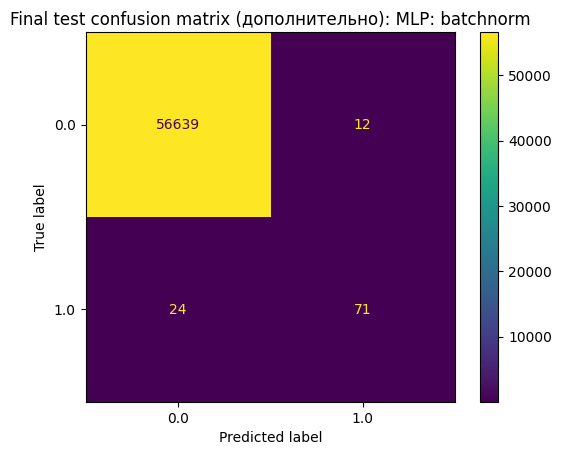

In [35]:
test_pred = (
    test_scores >= final_threshold_info["threshold"]
).astype(int)

ConfusionMatrixDisplay.from_predictions(
    y_test_np,
    test_pred,
    values_format="d",
)
plt.title(f"Final test confusion matrix (дополнительно): {final_name}")
plt.show()

В данном сравнении победил обычный MLP, но это не значит, что Autoencoder хуже - например, его можно применять, когда у нас меньше/совсем нет размеченных аномалий. Кроме того, если немного поэкспериментировать с архитектурой и обучением Autoencoder, можно добиться лучших результатов на этом и других датасетах.

# Идеи для дополнительных экспериментов и решения контеста

### 1. Denoising Autoencoder

На вход модели подаётся зашумлённый объект:

$\tilde{x} = x + \epsilon$

но восстанавливать нужно исходный `x`.

Это заставляет модель изучать более устойчивую структуру normal data.

### 2. Sparse Autoencoder

Добавить штраф, заставляющий latent representation быть разреженным.

### 3. Другие reconstruction losses

Сравнить:

- MSE;
- MAE;
- Huber loss.

### 4. Другие anomaly scores

Не обязательно усреднять squared error по всем признакам одинаково.

Можно попробовать:

- max reconstruction error;
- weighted reconstruction error;
- Mahalanobis distance в latent space;
- ансамбль нескольких автоэнкодеров.